# Tarea 2 — Estimación sin historia («arranque en frío»)

Predecir la tasa de deserción de una IES **solo con su contexto institucional y territorial** (formulación A: sin ninguna variable
de historia). La validación agrupa por IES, de modo que cada IES de prueba es nueva para el modelo, como una institución sin historia.
Este cuaderno recorre: las líneas base, los métodos que recomendó el profesor (KernelPCA, autoencoder, clusters), el cribado de la
grilla, la confirmación con el protocolo repetido, y la descripción de los clusters.

**Cómo leerlo.** Los resultados pesados (cribado de 120 configuraciones y confirmación 5 × 5) los produce `python run_tarea2.py`;
aquí se leen de `reports/resultados/` y se muestran. Lo que sí se calcula en el cuaderno es corto: la ilustración de cada método sobre un
pliegue y los clusters.

In [1]:
# Configuración: rutas relativas a la raíz del proyecto, librerías y avisos
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")  # avisos de KMeans/MKL en Windows y de convergencia: no cambian los resultados

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold

from src.config import load_config
from src.modelado import tarea2 as t2
from src.modelado.experimentos import parametros_experimentos
from src.modelado.metodos import AgregarClusters, AutoencoderPequeno, KernelPCAComoPCA
from src.modelado.particion import COLUMNAS_HISTORIA, COLUMNAS_HISTORIA_REZAGADA, NUNCA_EXPLICATIVAS, construir_preprocesador
from src.modelado.informe_tarea2 import describir_clusters, REFERENCIAS

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
cfg = load_config()
p, p_exp = t2.parametros_tarea2(cfg), parametros_experimentos(cfg)
print("Semilla del cribado:", p["semilla_cribado"], "| semillas de la confirmación:", p["semillas_confirmacion"])

Semilla del cribado: 11 | semillas de la confirmación: [201, 202, 203, 204, 205]


## 1. Datos y variables de la tarea

La formulación A usa solo variables de contexto (Saber 11, SNIES, TerriData, tamaño de la IES y los indicadores `falta_*` de los
bloques de años). **Ninguna** variable de historia (`tasa_t1`, `tasa_t2`, medias previas, etc.) ni de `NUNCA_EXPLICATIVAS`. El código
lo comprueba:

In [2]:
# Dataset sin cambios; X = variables explicativas de la tarea 2
df, X, y, numericas, categoricas = t2.preparar_datos(cfg)
prohibidas = set(COLUMNAS_HISTORIA) | set(COLUMNAS_HISTORIA_REZAGADA) | set(NUNCA_EXPLICATIVAS)
assert not prohibidas & set(X.columns), "una columna de historia entró a la tarea 2"
print(f"{len(df)} filas, {df.cod_ies.nunique()} IES; {len(numericas)} numéricas + {len(categoricas)} categóricas {categoricas}")
print("Columnas de historia o NUNCA_EXPLICATIVAS en X:", sorted(prohibidas & set(X.columns)))
print("Tasa de deserción: mediana", round(y.median(), 4), "| media", round(y.mean(), 4))

1928 filas, 295 IES; 33 numéricas + 2 categóricas ['sector', 'caracter']
Columnas de historia o NUNCA_EXPLICATIVAS en X: []
Tasa de deserción: mediana 0.0985 | media 0.1204


## 2. Líneas base (sin historia)

- **Mediana** del entrenamiento del pliegue.
- **Mediana por carácter × sector**, calculada en el entrenamiento; si el grupo no existe, la mediana global.

Así se ven las medianas por grupo con todos los datos (en la evaluación se recalculan en cada pliegue con solo su entrenamiento):

In [3]:
# Mediana de la tasa y número de IES-año por carácter × sector (descriptivo; la evaluación las calcula solo con el entrenamiento)
etiquetas = {"caracter": {"1": "técnica profesional", "2": "tecnológica", "3": "inst. universitaria", "4": "universidad"}, "sector": {"1": "oficial", "2": "privada"}}
tabla = (df.assign(caracter=df.caracter.astype(str).map(etiquetas["caracter"]), sector=df.sector.astype(str).map(etiquetas["sector"]))
         .groupby(["caracter", "sector"]).tasa_desercion.agg(filas="size", mediana="median", media="mean"))
display(tabla)

filas  mediana  media
caracter            sector                        
inst. universitaria oficial    119   0.1061 0.1119
                    privada    615   0.1121 0.1197
tecnológica         oficial     42   0.1373 0.1423
                    privada    176   0.1809 0.2192
técnica profesional oficial     52   0.2060 0.2207
                    privada     80   0.2064 0.2501
universidad         oficial    313   0.0743 0.0803
                    privada    531   0.0821 0.0830

## 3. Los métodos del profesor, ilustrados sobre un pliegue

Todos son *transformers* de scikit-learn que se ajustan **solo con el entrenamiento** del pliegue. Tomamos el primer pliegue del
GroupKFold por IES y mostramos qué hace cada uno (dimensiones, k elegido, parada temprana).

In [4]:
# Primer pliegue del GroupKFold por IES (semilla del cribado); preprocesamos con mediana y escalado SOLO con el entrenamiento
entrena, prueba = next(iter(GroupKFold(n_splits=5, shuffle=True, random_state=p["semilla_cribado"]).split(df, groups=df.cod_ies)))
pre = construir_preprocesador(numericas, categoricas, "mediana", p_exp["k_vecinos"]).fit(X.iloc[entrena])
Ztr, Zte = pre.transform(X.iloc[entrena]), pre.transform(X.iloc[prueba])
print(f"Entrenamiento: {Ztr.shape}  |  prueba: {Zte.shape}")

# PCA al 90 % de la varianza (lineal) y KernelPCA RBF con el MISMO número de componentes (no lineal)
pca = PCA(n_components=p_exp["varianza_pca"], svd_solver="full", random_state=0).fit(Ztr)
kpca = KernelPCAComoPCA(varianza=p_exp["varianza_pca"], gamma=p["kernel_pca"]["gamma"], random_state=p_exp["semilla"]).fit(Ztr)
print(f"PCA: {pca.n_components_} componentes retienen {pca.explained_variance_ratio_.sum():.1%} de la varianza")
print(f"KernelPCA (RBF, gamma = 1/n_variables): {kpca.n_componentes_} componentes; salida de prueba {kpca.transform(Zte).shape}")

Entrenamiento: (1552, 39)  |  prueba: (376, 39)


PCA: 16 componentes retienen 90.4% de la varianza
KernelPCA (RBF, gamma = 1/n_variables): 16 componentes; salida de prueba (376, 16)


In [5]:
# Autoencoder pequeño n -> 16 -> 8 -> 16 -> n con parada temprana (validación interna) y semilla fija; devuelve el cuello de botella (8)
ae = AutoencoderPequeno(**p["autoencoder"], random_state=p_exp["semilla"]).fit(Ztr)
print("Arquitectura (pesos):", [w.shape for w in ae.mlp_.coefs_])
print(f"Iteraciones: {ae.n_iter_} de {ae.max_iter} máximas | parada temprana: {ae.paro_temprano_}")
print("Cuello de botella (entrenamiento, prueba):", ae.transform(Ztr).shape, ae.transform(Zte).shape)
# error de reconstrucción en el entrenamiento y en la prueba (en unidades estandarizadas)
for nombre, Z in (("entrenamiento", Ztr), ("prueba", Zte)):
    print(f"Error cuadrático medio de reconstrucción ({nombre}): {np.mean((ae.mlp_.predict(Z) - Z) ** 2):.3f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(ae.mlp_.loss_curve_, label="pérdida de entrenamiento")
ax.plot(-np.array(ae.mlp_.validation_scores_), label="validación interna (−R²)")
ax.set_xlabel("iteración"); ax.legend(); ax.set_title("Autoencoder: parada temprana"); plt.show()

Arquitectura (pesos): [(39, 16), (16, 8), (8, 16), (16, 39)]
Iteraciones: 500 de 500 máximas | parada temprana: False
Cuello de botella (entrenamiento, prueba): (1552, 8) (376, 8)
Error cuadrático medio de reconstrucción (entrenamiento): 0.189
Error cuadrático medio de reconstrucción (prueba): 0.211


In [6]:
# Clusters: K-means sobre las variables territoriales e institucionales imputadas y escaladas (sin los indicadores falta_*),
# k por silueta entre 3 y 8. Agrega el cluster (one-hot) y las distancias a los centroides como variables NUEVAS.
ag = AgregarClusters(numericas, categoricas, **p["clusters"], random_state=p_exp["semilla"]).fit(X.iloc[entrena])
print("Silueta por k:", {k: round(v, 3) for k, v in ag.siluetas_.items()})
print(f"k elegido = {ag.k_}; columnas agregadas = {ag.transform(X.iloc[prueba]).shape[1]} (= 2k: one-hot + distancias)")

Silueta por k: {3: 0.193, 4: 0.173, 5: 0.197, 6: 0.201, 7: 0.197, 8: 0.171}
k elegido = 6; columnas agregadas = 12 (= 2k: one-hot + distancias)


## 4. Cribado (GroupKFold por IES, 5 pliegues, una semilla)

La grilla completa — objetivo × imputación × reducción × clusters × modelo — se evaluó con `run_tarea2.py`. Las diez mejores:

In [7]:
# Resultados del cribado (una fila por configuración y pliegue) y su resumen por configuración
cribado = pd.read_csv("reports/resultados/experimentos_tarea2_cribado.csv")
r = t2.resumen_cribado(cribado)
ref = r.set_index("configuracion").loc[t2.BASE_GRUPO, "mae_media"]
top = r.assign(mejora_vs_mediana_por_grupo_pct=100 * (ref - r.mae_media) / ref)
print(f"{(r.tipo == 'modelo').sum()} configuraciones evaluadas")
display(pd.concat([top[top.tipo == "linea_base"], top[top.tipo == "modelo"].head(10)])[
    ["configuracion", "mae_media", "mae_desv", "rmse_media", "r2_media", "mejora_vs_mediana_por_grupo_pct"]])

120 configuraciones evaluadas


,configuracion,mae_media,mae_desv,rmse_media,r2_media,mejora_vs_mediana_por_grupo_pct
8,base_mediana_grupo,0.0405,0.0058,0.0714,0.3066,0.0000
104,base_mediana,0.0501,0.0075,0.0880,-0.0650,-23.8367
0,ridge | logit | mediana | info_mutua | sin clu...,0.0394,0.0054,0.0688,0.3572,2.8054
1,ridge | logit | knn | info_mutua | sin clusters,0.0394,0.0055,0.0690,0.3542,2.5863
2,ridge | logit | mediana | ninguna | sin clusters,0.0397,0.0055,0.0691,0.3519,1.9265
3,ridge | logit | mediana | info_mutua | con clu...,0.0397,0.0050,0.0693,0.3472,1.8221
4,ridge | logit | knn | info_mutua | con clusters,0.0398,0.0051,0.0693,0.3476,1.6145
5,ridge | logit | knn | ninguna | sin clusters,0.0399,0.0057,0.0692,0.3503,1.5602
6,ridge | logit | knn | ninguna | con clusters,0.0401,0.0054,0.0697,0.3399,0.8948
7,ridge | logit | mediana | ninguna | con clusters,0.0402,0.0050,0.0699,0.3348,0.7687


### Efecto de cada metodología y de cada modelo

Primero el MAE medio de las configuraciones de cada nivel (promediando las demás decisiones) y después el contraste pareado: la
diferencia de MAE entre un nivel y la referencia en cada par de configuraciones que solo difieren en esa decisión (negativa = reduce el error).

In [8]:
niveles = pd.concat([t2.efecto_por_nivel(r, f) for f in t2.FACTORES]).reset_index(drop=True)
display(niveles[["factor", "nivel", "n_configuraciones", "mae_medio", "mae_mediano", "mae_minimo"]])
contrastes = pd.concat([t2.efecto_contraste(r, f, REFERENCIAS[f]) for f in t2.FACTORES]).reset_index(drop=True)
display(contrastes)

,factor,nivel,n_configuraciones,mae_medio,mae_mediano,mae_minimo
0,modelo,ridge,40,0.0449,0.0460,0.0394
1,modelo,xgboost,40,0.0480,0.0487,0.0451
2,modelo,random_forest,40,0.0490,0.0496,0.0462
3,objetivo,logit,60,0.0466,0.0465,0.0394
4,objetivo,ninguna,60,0.0480,0.0489,0.0413
5,imputacion,knn,60,0.0473,0.0478,0.0394
6,imputacion,mediana,60,0.0473,0.0479,0.0394
7,reduccion,info_mutua,24,0.0446,0.0460,0.0394
8,reduccion,ninguna,24,0.0448,0.0462,0.0397
9,reduccion,pca,24,0.0487,0.0489,0.0455


,factor,nivel,referencia,n_pares,dif_media,dif_mediana,prop_mejora
0,modelo,xgboost,ridge,40,0.0031,0.0029,0.0500
1,modelo,random_forest,ridge,40,0.0041,0.0039,0.0250
2,objetivo,logit,ninguna,60,-0.0014,-0.0012,1.0000
3,imputacion,knn,mediana,60,-0.0000,0.0000,0.4833
4,reduccion,info_mutua,ninguna,24,-0.0002,-0.0003,0.6667
5,reduccion,pca,ninguna,24,0.0040,0.0036,0.0000
6,reduccion,autoencoder,ninguna,24,0.0043,0.0034,0.0000
7,reduccion,kernel_pca,ninguna,24,0.0045,0.0040,0.0000
8,clusters,True,False,60,0.0000,0.0001,0.4500


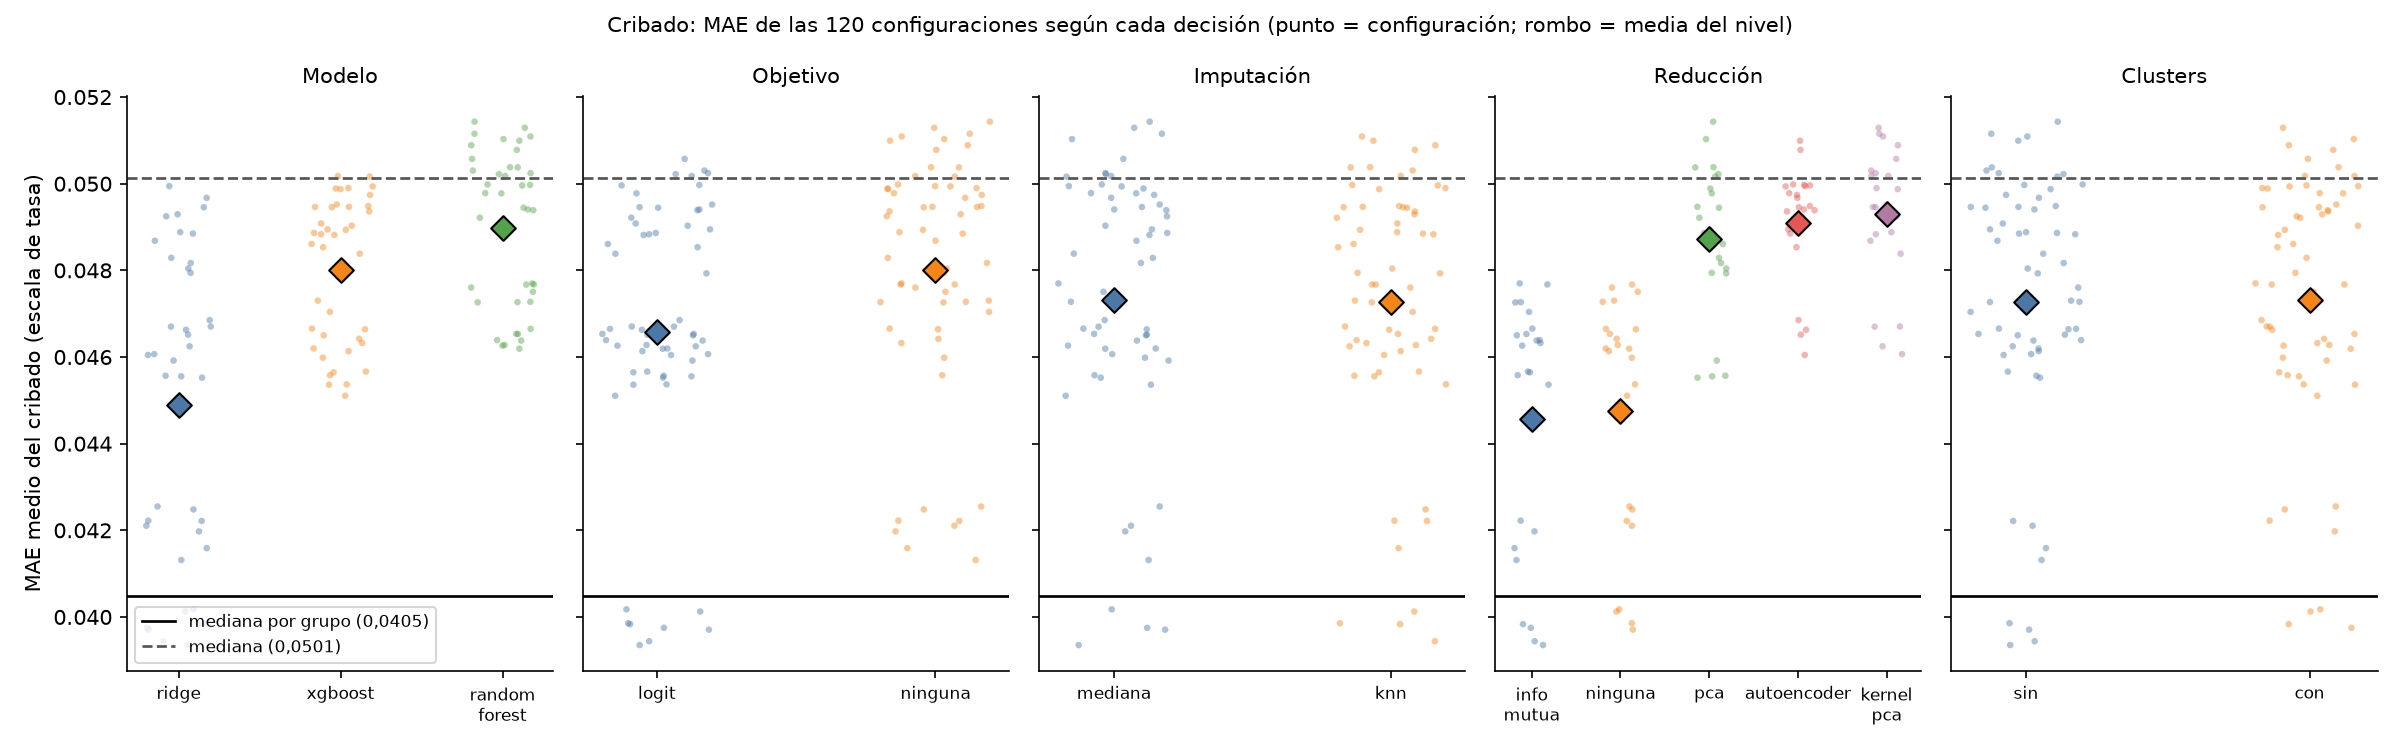

In [9]:
# Figura del cribado (la genera run_tarea2.py)
display(Image("reports/figuras/tarea2_metodologias.png"))

## 5. Confirmación (GroupKFold repetido 5 × 5, semillas distintas a las del cribado)

Con el protocolo de la v3: 25 ajustes por configuración, IC 95 % con la corrección de Nadeau y Bengio, y prueba pareada frente a la
mediana por carácter × sector (Wilcoxon y t corregida). Se confirman las dos líneas base, la mejor configuración de cada modelo y la mejor
de cada método de reducción **según el cribado**.

In [10]:
cr = pd.read_csv("reports/resultados/experimentos_tarea2_confirmacion_resumen.csv")
cols = ["configuracion", "mae_media", "mae_ic_inf", "mae_ic_sup", "r2_media", "mejora_grupo_pct", "p_wilcoxon_grupo", "p_t_grupo", "gana_grupo"]
display(cr.sort_values("mae_media")[cols])
# IC 95 % de cada configuración (barras) con las dos líneas base como referencia vertical
g = cr[cr.tipo == "modelo"].sort_values("mae_media", ascending=False)
fig, ax = plt.subplots(figsize=(9, 0.5 * len(g) + 1.8))
ax.errorbar(g.mae_media, range(len(g)), xerr=[g.mae_media - g.mae_ic_inf, g.mae_ic_sup - g.mae_media], fmt="o", color="#4c78a8", ecolor="#333", capsize=3)
for nombre, color, estilo in ((t2.BASE_GRUPO, "black", "-"), (t2.BASE_MEDIANA, "#555", "--")):
    ax.axvline(cr.set_index("configuracion").loc[nombre, "mae_media"], color=color, ls=estilo, label=nombre)
ax.set_yticks(range(len(g)), g.configuracion, fontsize=7); ax.set_xlabel("MAE (media e IC 95 %)"); ax.legend(); plt.show()

,configuracion,mae_media,mae_ic_inf,mae_ic_sup,r2_media,mejora_grupo_pct,p_wilcoxon_grupo,p_t_grupo,gana_grupo
2,ridge | logit | mediana | info_mutua | sin clu...,0.0396,0.0353,0.0440,0.3150,2.1995,0.0187,0.3489,0.7600
5,ridge | logit | mediana | ninguna | sin clusters,0.0399,0.0356,0.0443,0.3119,1.4579,0.1135,0.5618,0.6000
1,base_mediana_grupo,0.0405,0.0356,0.0454,0.2704,0.0000,NaN,NaN,0.0000
3,xgboost | logit | mediana | ninguna | con clus...,0.0453,0.0395,0.0512,0.0153,-11.8326,0.0000,0.0665,0.2000
6,ridge | logit | mediana | pca | sin clusters,0.0454,0.0380,0.0528,0.1443,-12.0465,0.0000,0.0195,0.0400
7,ridge | logit | knn | autoencoder | sin clusters,0.0458,0.0382,0.0535,0.1266,-13.0861,0.0000,0.0139,0.0400
8,ridge | logit | mediana | kernel_pca | sin clu...,0.0461,0.0389,0.0533,0.1232,-13.7684,0.0000,0.0048,0.0400
4,random_forest | logit | mediana | ninguna | co...,0.0478,0.0428,0.0528,-0.0706,-17.9443,0.0000,0.0118,0.0400
0,base_mediana,0.0501,0.0425,0.0577,-0.0725,-23.6214,0.0000,0.0002,0.0000


## 6. Clusters: qué son

K-means ajustado con **todas** las filas (solo para describir; en la evaluación se ajusta dentro de cada pliegue). La proyección
en 2D con PCA es solo para visualizar. Los nombres cortos son una interpretación manual a partir de los municipios sede dominantes.

k = 6 | silueta por k: {3: 0.177, 4: 0.176, 5: 0.194, 6: 0.201, 7: 0.178, 8: 0.18}


,cluster,nombre,n_filas,n_ies,municipios,pct_oficial,pct_universidad,matricula_mediana,tasa_mediana,punt_global_media_t1,pct_estrato_bajo_t1,td_nbi_pct_t1,td_ipm_censo_t1,td_cob_bruta_media_t1,td_mdm_t1
0,0,Bogotá,597,93,Bogotá (100 %),10.5528,35.1759,3802.0000,0.1143,272.4159,55.3496,7.5971,20.0201,90.0290,77.1239
1,1,Ciudades intermedias de alta cobertura,246,74,"Bucaramanga (24 %), Pereira (13 %), Tunja (11 %)",30.0813,54.4715,3337.0000,0.0852,273.5172,57.7733,9.6460,23.2353,104.9517,70.6000
2,2,Periferia con pobreza alta,108,25,"Montería (14 %), Quibdó (13 %), Sincelejo (9 %)",71.2963,60.1852,1323.2500,0.1078,242.5671,89.8732,46.0959,63.6225,86.1538,50.7831
3,3,Grandes ciudades con buen desempeño municipal,379,70,"Medellín (55 %), Barranquilla (28 %), Bucarama...",21.6359,40.3694,4052.0000,0.0946,257.8147,59.4943,11.8324,27.8436,97.2259,78.2874
4,4,Cali y Manizales: baja cobertura,219,39,"Cali (63 %), Manizales (16 %), Palmira (8 %)",29.2237,47.9452,2664.5000,0.0979,259.9215,56.9432,9.0404,25.5098,79.5198,75.0543
5,5,"Pobreza media-alta, estrato bajo",379,86,"Cartagena (18 %), Popayán (7 %), Cúcuta (6 %)",43.7995,46.7018,2703.0000,0.0945,255.0656,76.8674,19.4589,38.9841,91.6336,58.5717


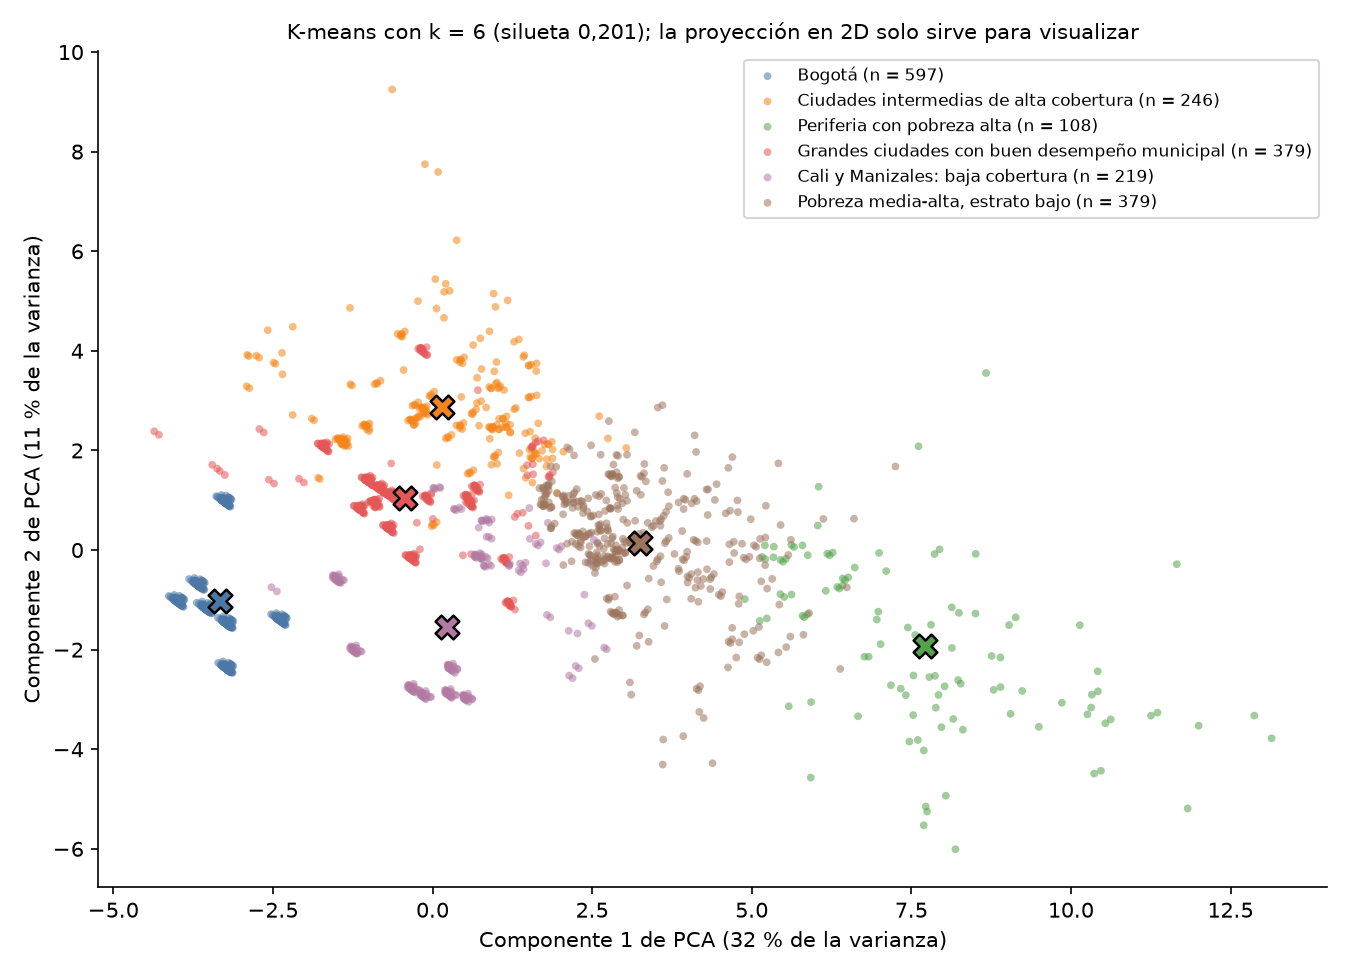

In [11]:
ag_total, df_cl, etiquetas = t2.ajustar_clusters(cfg, df)
desc, medias = describir_clusters(df_cl, X, etiquetas, numericas)
siluetas = {k: round(v, 3) for k, v in ag_total.siluetas_.items()}
print(f"k = {ag_total.k_} | silueta por k: {siluetas}")
display(desc[["cluster", "nombre", "n_filas", "n_ies", "municipios", "pct_oficial", "pct_universidad", "matricula_mediana", "tasa_mediana",
              "punt_global_media_t1", "pct_estrato_bajo_t1", "td_nbi_pct_t1", "td_ipm_censo_t1", "td_cob_bruta_media_t1", "td_mdm_t1"]])
display(Image("reports/figuras/clusters.png"))

In [12]:
# Cómo cambia la composición de cada cluster con los años (si crece o se achica, el cluster recoge también cambios de las fuentes)
display(pd.crosstab(df_cl.assign(cluster=etiquetas).cluster.map(dict(zip(desc.cluster, desc.nombre))), df_cl.anio))

anio,2015,2016,2017,2018,2019,2020,2021
cluster,,,,,,,
Bogotá,87,88,85,86,84,85,82
Cali y Manizales: baja cobertura,28,30,29,30,34,33,35
Ciudades intermedias de alta cobertura,11,16,35,32,37,46,69
Grandes ciudades con buen desempeño municipal,62,63,52,54,48,51,49
Periferia con pobreza alta,22,21,21,18,15,7,4
"Pobreza media-alta, estrato bajo",69,62,52,57,56,51,32


## 7. Conclusiones

(Tomadas de `reports/resultados_tarea2.md`; todas las cifras salen de la corrida.)

- **¿Alguna configuración supera a la línea base por carácter × sector?** De 7 configuraciones confirmadas, 0 tienen menor error con significancia en las dos pruebas (Wilcoxon y t corregida < 0,05), 2 tienen menor error medio sin esa significancia y 5 no mejoran a la base. La de menor MAE es `ridge | logit | mediana | info_mutua | sin clusters`: 0,0396 [0,0353; 0,0440] frente a 0,0405 [0,0356; 0,0454] de la mediana por grupo (+2,2 %; p Wilcoxon 0,019, p t corregida 0,349, gana en 76 % de los pliegues); mejora; significativa solo en Wilcoxon, que no corrige la dependencia. Sin ajustar por comparaciones múltiples; con Bonferroni (7 comparaciones) la p t corregida de esa configuración sería 1,000. Frente a la mediana global la mejor mejora +20,9 % (p Wilcoxon < 0,001). La mediana por grupo mejora a la global en +19,1 % de MAE (0,0405 frente a 0,0501).
- **¿Qué método de reducción ayuda?** En el cribado, efecto de cada reducción frente a no reducir con las demás decisiones iguales (diferencia de MAE; negativa = ayuda):
  - `info_mutua`: -0,0002 en promedio (24 pares; reduce el error en 67 % de ellos).
  - `pca`: 0,0040 en promedio (24 pares; reduce el error en 0 % de ellos).
  - `autoencoder`: 0,0043 en promedio (24 pares; reduce el error en 0 % de ellos).
  - `kernel_pca`: 0,0045 en promedio (24 pares; reduce el error en 0 % de ellos).
  En la confirmación, la mejor configuración de cada reducción frente a la mejor sin reducción (`ridge | logit | mediana | ninguna | sin clusters`) (diferencia = MAE sin reducir − MAE con reducción; positiva = la reducción ayuda):
  - `ridge | logit | mediana | info_mutua | sin clusters`: 0,0003 [-0,0005; 0,0011] (mejora; significativa solo en Wilcoxon, que no corrige la dependencia; p Wilcoxon 0,042, p t corregida 0,453).
  - `ridge | logit | mediana | pca | sin clusters`: -0,0055 [-0,0104; -0,0005] (empeora, significativa en ambas pruebas; p Wilcoxon < 0,001, p t corregida 0,032).
  - `ridge | logit | mediana | kernel_pca | sin clusters`: -0,0062 [-0,0106; -0,0017] (empeora, significativa en ambas pruebas; p Wilcoxon < 0,001, p t corregida 0,009).
  - `ridge | logit | knn | autoencoder | sin clusters`: -0,0059 [-0,0109; -0,0009] (empeora, significativa en ambas pruebas; p Wilcoxon < 0,001, p t corregida 0,023).
- **¿PCA sigue empeorando y las alternativas no lineales lo corrigen?** PCA sigue empeorando (diferencia media 0,0040 frente a no reducir, en el cribado). KernelPCA: 0,0045; autoencoder: 0,0043. Ninguna alternativa no lineal reduce el daño de PCA.
- **¿Ayudan los clusters como variables nuevas?** En el cribado, con clusters frente a sin clusters (demás decisiones iguales): diferencia media de MAE 0,0000 (60 pares; reduce el error en 45 % de ellos).
- **Modelos** (MAE medio de sus configuraciones en el cribado): ridge (0,0449), xgboost (0,0480), random_forest (0,0490).

**Sobre LDA.** No se implementa LDA: es un método lineal y supervisado para **clases** (busca las direcciones que mejor separan categorías), y aquí el objetivo es una tasa continua. Solo aplicaría discretizando la tasa (por ejemplo, en terciles), lo que descarta información del objetivo y convierte la regresión en una clasificación, con otro problema y otras métricas.